---
title: Hidden Markov Model with Control (Part 2)
subtitle: Control a Roomba using Active Inference and RxInfer
author: Kobus Esterhuysen
date: '2024-05-20'
date-modified: last-modified
categories:
  - Bayesian Inference
  - Active Inference
  - RxInfer
  - Julia
image: HMMwithControl.png
format:
  html:
    toc: true
    toc-depth: 4
    toc-expand: true
    toc-title: TOC
    code-fold: false
---

In [45]:
#| hide
# BASED ON
  # HMMwithControl2_PORT^v2.ipynb
  # HMMwithControl_PORT^v6.ipynb

# DONE
# v1 starts ------------------------------------------------
# Julia 1.11.6 --> to 1.12.7
# RxInfer 3.6.0 --> 5.5.2
# Plots 1.40.1 --> 1.41.7
# latest RxInfer
# latest Plots
# clean for publication
# v3 starts ------------------------------------------------
# align with ActiveInference_Notebook_Standards.md v1.7
#     round brackets for members: s^{(t,0)}, A^{(m)}, B^{*(0)}, hat before the asterisk
#     code members ı…ı: _Bˣı0ı, _Aˣı0ı, _Aı0ı; index constants whereabouts_n, surface_m, illumination_m
#     names: Room → whereabouts, Texture → surface, Light (the modality) → illumination
#     skeleton filled in: text conventions, terms, assumptions, symbols table,
#         4.5.6, 4.7 conclusion and outlook, appendix A, appendix B
#     designer objectives J_track, J_misread, J_B, J_A
#     plot helpers step_x, step_y and the series font sizes
#     conclusion counts taken from this notebook's stored run (seed 42):
#         7 ticks fixed and 6 new errors
#     the comparison stays one seed; a 30-seed average is a next step
# v4 starts ------------------------------------------------
# series names: value livingroom → living room
# TODO


# Hidden Markov Model with Control (Part 2)

## 1 BUSINESS UNDERSTANDING

This is the second part of Hidden Markov Model with Control. The series adds control to the Hidden Markov Model example from RxInfer, on the way to a scheduling project that uses active inference. In the first part the Roomba was tracked with a camera alone. This part still only tracks it.

The names of model variables are written in italic lower case, such as *whereabouts*, and their values in double quotes, such as "bedroom". Section 4.1 describes these conventions, and Appendix A gives their motivation.

**The apartment.** The Roomba moves through an apartment of three rooms: a bedroom, a living room, and a bathroom.

**The sensors.** The Roomba now carries two sensors.

- A camera reports the *surface* under the Roomba: hardwood in the bedroom, carpet in the living room, and tiles in the bathroom.
- A light sensor reports *illumination*. The living room has skylights and is usually bright. The bathroom has no windows and is usually dark. The bedroom is in between.

Both sensors are noisy, and they fail in different ways. When the camera cannot tell hardwood from tiles, *illumination* can still separate the bedroom from the bathroom. Section 4.6 tests whether that helps.

**What this part adds.** The agent infers the *whereabouts* at each tick and learns three matrices: the transition matrix $\boldsymbol{B}^{(0)}$, and one observation matrix per sensor, $\boldsymbol{A}^{(0)}$ for *surface* and $\boldsymbol{A}^{(1)}$ for *illumination*. Relative to the original RxInfer example, the roles of $A$ and $B$ are swapped. That example follows the engineering convention and uses $A$ for state transitions. Here, as in the active inference literature, $\mathbf{A}$ holds the observation matrices and $\mathbf{B}$ the state transition matrices.

Terms from the first part, used here without a second definition: hidden Markov model, generative process, generative model, state factor, observation modality, variational inference.

### Terms added in this part

**Tick.** One time step. A run covers $T + 1$ ticks, $t = 0, \ldots, T$.

**Light sensor.** The Roomba's second sensor. It reports the modality *illumination*, whose values are "low" and "high".

### Assumptions

The transition probabilities and the two sensor matrices in section 4.3.4 are chosen for this apartment, not measured from a Roomba. Appendix B records the reasons. The same section states the numbers.

### Structure of the code

This part uses the series protocol. One tick is: the environment moves, the agent observes, and, once the whole trajectory is recorded, the agent infers. There is no action in the loop yet.

- `create_envir(...)` returns `execute`, `observe`, and `state`, and draws every random sample from `MersenneTwister(seed)`
    - `execute()` advances one tick. With no action to carry out, the *whereabouts* moves by $\boldsymbol{B}^{\ast(0)}$ and both sensors are drawn from $\boldsymbol{A}^{\ast(0)}$ and $\boldsymbol{A}^{\ast(1)}$
    - `observe()` returns the observation tuple $\hat{\mathbf{o}}^{(t)}$
    - `state()` returns the true state $\hat{\mathbf{s}}^{\ast(t)}$, for evaluation only
- `create_agent(...)` returns `compute`
    - `compute()` infers $Q(s^{(t,0)})$ for $t = 0, \ldots, T$ and learns $\boldsymbol{A}^{(0)}$, $\boldsymbol{A}^{(1)}$, and $\boldsymbol{B}^{(0)}$ from the whole trajectory in one variational inference
    - `act()`, `future()`, and `slide()` are not in this part. The posterior is not yet stepped forward one tick at a time


In [1]:
versioninfo() ## Julia version

Julia Version 1.12.7
Commit 6d172b025e4 (2026-08-15 08:05 UTC)
Build Info:
  Official https://julialang.org release
Platform Info:
  OS: Linux (x86_64-linux-gnu)
  CPU: 12 × Intel(R) Core(TM) i7-8700B CPU @ 3.20GHz
  WORD_SIZE: 64
  LLVM: libLLVM-18.1.7 (ORCJIT, skylake)
  GC: Built with stock GC
Threads: 1 default, 1 interactive, 1 GC (on 12 virtual cores)


In [2]:
import Pkg
Pkg.add(Pkg.PackageSpec(;name="RxInfer"))
Pkg.add(Pkg.PackageSpec(;name="Random"))
Pkg.add(Pkg.PackageSpec(;name="Plots"))
Pkg.add(Pkg.PackageSpec(;name="XLSX"))
Pkg.add(Pkg.PackageSpec(;name="DataFrames"))
Pkg.add(Pkg.PackageSpec(;name="BenchmarkTools"))
Pkg.add(Pkg.PackageSpec(;name="Distributions"))
Pkg.add(Pkg.PackageSpec(;name="OffsetArrays"))

using RxInfer, Random, BenchmarkTools, Distributions, Plots, XLSX, DataFrames, OffsetArrays

     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/envir

In [3]:
Pkg.status()

Status `~/.julia/environments/v1.12/Project.toml`
  [6e4b80f9] BenchmarkTools v1.8.0
  [a93c6f00] DataFrames v1.8.2
  [31c24e10] Distributions v0.25.132
  [6fe1bfb0] OffsetArrays v1.17.0
  [91a5bcdd] Plots v1.41.7
  [86711068] RxInfer v6.1.0
  [fdbf4ff8] XLSX v0.13.2
  [9a3f8284] Random v1.11.0


## 2 DATA UNDERSTANDING

The data are simulated. One tick is one move of the Roomba. A run covers $T + 1 = 600$ ticks, $t = 0, \ldots, T$, with $T = 599$.

Three kinds of one-hot vector come up in the series. This part records two of them.

- **Observations**, which the agent receives. The tuple is $\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{(t,0)}, \hat{\boldsymbol{o}}^{(t,1)}\big)$.
    - *surface*, modality 0: "hardwood", "carpet", "tiles"
    - *illumination*, modality 1: "low", "high"
- **Actions.** This part has none. The agent does not choose a control, and nothing is recorded for $t = 0, \ldots, T-1$.
- **True states**, which the agent never sees. The tuple is $\hat{\mathbf{s}}^{\ast(t)} = \big(\hat{\boldsymbol{s}}^{\ast(t,0)}\big)$.
    - *whereabouts*, factor 0: "bedroom", "living room", "bathroom"

In a one-hot vector, the component that equals 1 is the value that occurred. The category and the one-hot are tied by $\hat{s}^{\ast(t,0)[i]} = \delta_{i\,\hat{s}^{\ast(t,0)}}$ and $\hat{o}^{(t,m)[i]} = \delta_{i\,\hat{o}^{(t,m)}}$. The code stores the one-hot.

A measured log from a real Roomba would replace this simulation. The matrices in section 4.3.4 would then be estimates rather than the numbers chosen here.

The agent works with the observations only. It chooses no actions in this part. The true states are kept for evaluation: they are what $J_{\text{track}}$ and $J_{\text{misread}}$ compare the inferred *whereabouts* against, and they are the columns the learned matrices are checked against.


## 3 DATA PREPARATION

The simulation is used as recorded. Nothing is cleaned. Trajectories are indexed from 0, so index $t$ is time $t$.

- `Lôː` holds the observations $\hat{\mathbf{o}}^{(t)}$ for $t = 0, \ldots, T$. Each entry is a tuple, *surface* then *illumination*.
- `Lŝˣː` holds the true states $\hat{\mathbf{s}}^{\ast(t)}$ for $t = 0, \ldots, T$, for evaluation only.
- `Lsː` holds the marginal beliefs $Q(s^{(t,0)})$ for $t = 0, \ldots, T$, filled when `compute` returns.
- There is no `Lûː`. This part records no actions.

The index constants are `whereabouts_n`, `surface_m`, and `illumination_m`. The label vectors are `whereabouts_labels`, `surface_labels`, and `illumination_labels`, and `s_dims` and `o_dims` are their lengths.

RxInfer's vectors are indexed from 1. Conversion happens only at that boundary.

- Going in, `parent` copies `Lôː` into one 1-based vector of one-hots per modality: `_ôı0ıː_data` for *surface* and `_ôı1ıː_data` for *illumination*.
- Coming out, `offset0` re-indexes the posterior trajectory, so `Lsː[t]` is $Q(s^{(t,0)})$.

Inside the `@model`, `sː[t+1]` still holds time $t$, because that vector starts at 1.

The next cell defines `tuple0`, `offset0`, the step-plot helpers `step_x` and `step_y`, the font sizes, and the index constants.


In [4]:
## tuple0(x...): a 0-based tuple (x^{(0)}, ..., x^{(N)}), one entry per argument.
##   - tuple0(v) wraps v; it does not re-index v itself
##   - the range 0:N follows from the number of arguments
##   - entries may differ in shape, as likelihood matrices do across modalities
## Returns an OffsetVector (mutable), not a Julia Tuple.
tuple0(x...) = OffsetVector(collect(x), 0:length(x)-1)

## offset0(v): re-index an existing vector from 0, for a trajectory t = 0, ..., T.
## Unlike tuple0, it does not wrap v; it shifts v's own indices.
offset0(v) = OffsetVector(v, 0:length(v)-1)

## step_x(n): the n + 1 edges of n tiles. Tick t is drawn from t - 0.5 to t + 0.5.
step_x(n) = range(-0.5, n - 0.5; length=n + 1)

## step_y(v): repeat the last value so a step series lines up with those tiles.
step_y(v) = vcat(collect(v), last(v))

## Series font sizes: titles 13, axis labels 12, legend 10, ticks 9.
default(titlefontsize=13, guidefontsize=12, legendfontsize=10, tickfontsize=9)

## Factor index n, modality index m. Notebooks before v1.7 used a _f suffix.
whereabouts_n = 0
surface_m = 0
illumination_m = 1

## Values, in index order, identical to the strings in the text.
whereabouts_labels = ["bedroom", "living room", "bathroom"]
surface_labels = ["hardwood", "carpet", "tiles"]
illumination_labels = ["low", "high"]

s_dims = [length(whereabouts_labels)]
o_dims = [length(surface_labels), length(illumination_labels)]


2-element Vector{Int64}:
 3
 2

**Why `tuple0()`.**

`tuple0` builds a tuple of factors or modalities. `OffsetVector` is the array underneath it, and it is easy to offset the wrong level with it. The six reasons below are the ones that decided the helper. Appendix B records the choice.

1. **It prevents a level mix-up.** With `OffsetVector`, the wrong level is a valid program:

```julia
    OffsetVector([1.0, 0.0, 0.0], 0:2)    ## the one-hot vector itself, re-indexed 0:2 (wrong level)
    OffsetVector([[1.0, 0.0, 0.0]], 0:0)  ## a tuple containing the one-hot vector (intended)
    tuple0([1.0, 0.0, 0.0])               ## the same as the second line
```

    The first line is the one-hot $\hat{\boldsymbol{s}}^{\ast(0,0)}$, indexed from 0. The intended object is the tuple $\hat{\mathbf{s}}^{\ast(0)} = \big(\hat{\boldsymbol{s}}^{\ast(0,0)}\big)$. Later code that indexes `[whereabouts_n]` would then get a single number instead of a vector. `tuple0` always wraps each argument as one entry.

2. **The index range is computed automatically.** Writing the range by hand means it has to agree with the number of entries. Adding a modality to `LAˣ` and forgetting to change `0:0` to `0:1` fails at best. `tuple0` takes the range from the number of arguments.

3. **It reads like the math.** `tuple0(_Aˣı0ı, _Aˣı1ı)` is $\big(\boldsymbol{A}^{\ast(0)}, \boldsymbol{A}^{\ast(1)}\big)$. `OffsetVector([_Aˣı0ı, _Aˣı1ı], 0:1)` adds a Julia range that is not part of the math.

4. **It states the intent.** `OffsetVector` means an array with shifted indices. `tuple0` means a tuple of factors or modalities, as in (10.33). A search for `tuple0(` finds every such tuple.

5. **There is one place to change things.** A check that every column of every $\boldsymbol{A}$ and $\boldsymbol{B}$ sums to 1, or a switch to another 0-based type, is one function.

6. **Entries of different shapes just work.** `tuple0(_Aˣı0ı, _Aˣı1ı)` with a $3\times 3$ matrix and a $2\times 3$ matrix is a tuple of likelihood matrices with different numbers of observations.

A named member uses `ı…ı`, so $\boldsymbol{B}^{\ast(0)}$ is `_Bˣı0ı`. The tuple `LBˣ` holds that matrix at `LBˣ[whereabouts_n]`, which is the same array.


## 4 MODELING
### 4.1 Narrative

Time, factors, and modalities are members of an ordered collection, written in round brackets with time first, as in $s^{(t,0)}$ and $\boldsymbol{A}^{(m)}$. A position along an array is written in square brackets, as in $s^{(t,0)[i]}$. A tuple is upright bold, a single array is italic bold, and a scalar or a single random variable is plain. An asterisk marks the environment and sits before the indices: $\boldsymbol{B}^{\ast(0)}$, $\hat{\boldsymbol{s}}^{\ast(t,0)}$.

**Text conventions.**

- Italic lower case is the name of a model variable. The names in this notebook are *whereabouts*, *surface*, and *illumination*.
- Double quotes are a value of a variable. The values are "bedroom", "living room", "bathroom", "hardwood", "carpet", "tiles", "low", and "high".
- Bold is a low-level heading or a label.

Italics and bold are not used for emphasis. Appendix A gives the motivation.

**Symbols.**

| Math | Code | Meaning |
|---|---|---|
| *whereabouts*, $s^{(t,0)}$ | `whereabouts_n`, `whereabouts_labels` | state factor 0. Values "bedroom", "living room", "bathroom" |
| *surface*, $o^{(t,0)}$ | `surface_m`, `surface_labels` | modality 0, from the camera. Values "hardwood", "carpet", "tiles" |
| *illumination*, $o^{(t,1)}$ | `illumination_m`, `illumination_labels` | modality 1, from the light sensor. Values "low", "high" |
| $\mathbf{A}^{\ast}$, $\boldsymbol{A}^{\ast(0)}$, $\boldsymbol{A}^{\ast(1)}$ | `LAˣ`, `_Aˣı0ı`, `_Aˣı1ı` | environment likelihoods. *surface* is $3\times 3$, *illumination* is $2\times 3$ |
| $\mathbf{B}^{\ast}$, $\boldsymbol{B}^{\ast(0)}$ | `LBˣ`, `_Bˣı0ı` | environment transition of *whereabouts*, $3\times 3$ |
| $\boldsymbol{D}^{\ast(0)}$ | the one-hot passed to `create_envir` | environment initial distribution. A point mass on "bedroom" |
| $\mathbf{A}$, $\boldsymbol{A}^{(0)}$, $\boldsymbol{A}^{(1)}$ | `_Aı0ı`, `_Aı1ı` inside `@model` | agent likelihoods, learned |
| $\boldsymbol{B}^{(0)}$ | `_Bı0ı` inside `@model` | agent transition, learned |
| $\boldsymbol{D}^{(0)}$ | `fill(1/3, 3)` on `sː[1]` | agent initial prior, uniform |
| $\check{\boldsymbol{a}}^{(0)}$, $\check{\boldsymbol{a}}^{(1)}$, $\check{\boldsymbol{b}}^{(0)}$ | the `DirichletCollection` arguments | prior concentrations |
| $\bar{\boldsymbol{A}}^{(0)}$, $\bar{\boldsymbol{A}}^{(1)}$, $\bar{\boldsymbol{B}}^{(0)}$ | `_Āı0ı`, `_Āı1ı`, `_B̄ı0ı` | posterior means after `compute` |
| $\hat{\mathbf{s}}^{\ast(t)}$, $\hat{\boldsymbol{s}}^{\ast(t,0)}$ | `Lŝˣₜ`, `Lŝˣₜ[whereabouts_n]` | true state tuple, and the *whereabouts* one-hot |
| $\hat{s}^{\ast(t,0)}$ | `argmax` of that one-hot | true category. Julia's `argmax` counts from 1 |
| $\hat{\mathbf{o}}^{(t)}$, $\hat{\boldsymbol{o}}^{(t,0)}$, $\hat{\boldsymbol{o}}^{(t,1)}$ | `Lôₜ`, `Lôₜ[surface_m]`, `Lôₜ[illumination_m]` | received one-hots |
| $\hat{\mathbf{s}}^{\ast(0:T)}$, $\hat{\mathbf{o}}^{(0:T)}$ | `Lŝˣː`, `Lôː` | trajectories |
| $\boldsymbol{s}^{(t,0)}$, $Q(s^{(t,0)})$ | `Lsː[t]` | marginal belief at time $t$ |
| $t$, $T$ | `t`, `T` | time, and the last tick. $T = 599$ |

This part has no control factor, no policy, no $\log\boldsymbol{C}$, and no $\boldsymbol{G}$.

**A second modality.** The first part observed *surface* only. This part adds *illumination*, with its own likelihood $\boldsymbol{A}^{(1)}$, which the agent learns from a flat prior.

**The matrices are learned.** The agent is not given $\boldsymbol{A}^{\ast(0)}$, $\boldsymbol{A}^{\ast(1)}$, or $\boldsymbol{B}^{\ast(0)}$. It learns $\boldsymbol{A}^{(0)}$, $\boldsymbol{A}^{(1)}$, and $\boldsymbol{B}^{(0)}$, and it tracks *whereabouts* from the two observation streams together.

**Same path, two agents.** Section 4.6 runs a camera-only agent on the same $\hat{\boldsymbol{o}}^{(t,0)}$ as the two-sensor agent, so the comparison is the light sensor rather than a different random path.

Appendix B records the modeling choices, including the numbers in the matrices and the decision to keep this comparison on one seed.

**Realized values.** A hat is something that has happened. The category is plain, $\hat{s}^{\ast(t,0)}$ and $\hat{o}^{(t,m)}$. The one-hot that the code stores is bold, $\hat{\boldsymbol{s}}^{\ast(t,0)}$ and $\hat{\boldsymbol{o}}^{(t,m)}$, and $\hat{o}^{(t,m)[i]} = \delta_{i\,\hat{o}^{(t,m)}}$. A bold symbol without a hat is a distribution. The belief $\boldsymbol{s}^{(t,0)}$ is a probability vector. Inside $P(\cdot)$, $Q(\cdot)$, and $\mathcal{Cat}(\cdot)$ the random variable is plain: $s^{(t,0)}$, $o^{(t,m)}$.

The asterisk marks the environment. $\hat{\mathbf{o}}^{(t)}$ has no asterisk: the environment draws it and the agent receives the same tuple.

**An expected observation.** Suppose $\boldsymbol{s}^{(t,0)} = [0.7, 0.2, 0.1]^{\top}$ and $\boldsymbol{A}^{(0)}$ equals $\boldsymbol{A}^{\ast(0)}$. Then

$$
\boldsymbol{A}^{(0)}\boldsymbol{s}^{(t,0)} =
\begin{bmatrix} 0.9 & 0.05 & 0.05 \\ 0.05 & 0.9 & 0.05 \\ 0.05 & 0.05 & 0.9 \end{bmatrix}
\begin{bmatrix} 0.7 \\ 0.2 \\ 0.1 \end{bmatrix}
=
\begin{bmatrix} 0.645 \\ 0.22 \\ 0.135 \end{bmatrix}
$$

so the agent expects "hardwood" with probability 0.645, "carpet" with probability 0.22, and "tiles" with probability 0.135. If the camera then reports "carpet", the received one-hot is $\hat{\boldsymbol{o}}^{(t,0)} = [0, 1, 0]^{\top}$, and the belief $\boldsymbol{s}^{(t,0)}$ moves toward "living room".

**Code symbols.** `L` is a tuple, `_` is an array, `ˣ` is the environment, `ː` is a trajectory, and `ₜ` is the current tick. A member is bracketed with `ı…ı`: `_Bˣı0ı` is $\boldsymbol{B}^{\ast(0)}$, and it is also `LBˣ[whereabouts_n]`. Appendix A gives the RxInfer boundary, where the model cannot index a tuple and the member index sits in the name, as in `_Aı0ı`.


### 4.2 Core Elements

**Metrics.**

- **tracking**, $J_{\text{track}}$: the fraction of ticks at which the most probable value of $\boldsymbol{s}^{(t,0)}$ equals $\hat{s}^{\ast(t,0)}$. Higher is better. This is the main measure.
- **tracking on a misread**, $J_{\text{misread}}$: the same fraction, restricted to ticks where the *surface* category is not the one that belongs to the true *whereabouts* (hardwood with "bedroom", carpet with "living room", tiles with "bathroom"). Higher is better.
- **transition error**, $J_{\text{B}}$: the largest absolute entrywise gap between $\bar{\boldsymbol{B}}^{(0)}$ and $\boldsymbol{B}^{\ast(0)}$. Lower is better.
- **surface error**, $J_{\text{A}}$: the largest absolute entrywise gap between $\bar{\boldsymbol{A}}^{(0)}$ and $\boldsymbol{A}^{\ast(0)}$. Lower is better.

The baselines are ways to track the Roomba without using both sensors. One is to read the *surface* as the *whereabouts*: "hardwood" means "bedroom", "carpet" means "living room", and "tiles" means "bathroom". Another is the same generative model with the camera only, ignoring *illumination*. A good agent should beat the surface reading, including on the ticks where that reading is wrong. Whether it beats the camera-only model is the question of this part.

**Decisions.** The agent chooses nothing. Each tick the *whereabouts* changes under $\boldsymbol{B}^{\ast(0)}$, and the agent only infers where the Roomba is.

**Sources of uncertainty.**

*In the environment:* the next *whereabouts* is random under $\boldsymbol{B}^{\ast(0)}$, and both sensors are random under $\boldsymbol{A}^{\ast(0)}$ and $\boldsymbol{A}^{\ast(1)}$. The camera sometimes reports the wrong *surface*. *Illumination* varies inside a room: the living room is dark at night or under heavy cloud, and the bathroom is bright when its light is on. The initial *whereabouts* is not random in the environment. The Roomba starts at "bedroom".

*On the agent's side:* the agent never receives $\hat{s}^{\ast(t,0)}$. It has $\boldsymbol{s}^{(t,0)}$ only. It is not given $\mathbf{A}^{\ast}$ or $\mathbf{B}^{\ast}$. Its own $\mathbf{A}$ and $\mathbf{B}$ start from the Dirichlet priors in section 4.5.4 and are learned. The prior on $\boldsymbol{A}^{(1)}$ is flat on purpose, so the light sensor's matrix is not a copy of the environment's.


### 4.3 System-Under-Steer / Environment / Generative Process

Before the agent runs, this section states the process that produces the data. The *whereabouts* is categorical, with three values, because the apartment has three rooms. At time $t$ the true state is

$$
\hat{\mathbf{s}}^{\ast(t)} = \big(\hat{\boldsymbol{s}}^{\ast(t,0)}\big)
$$

and the category is $s^{\ast(t,0)} \in \{\text{bedroom}, \text{living room}, \text{bathroom}\}$.

The environment's initial distribution is $\boldsymbol{D}^{\ast(0)} = [1, 0, 0]^{\top}$, a point mass on "bedroom". Some rooms connect and some do not. There is no door between the bedroom and the living room, so the Roomba passes through the bathroom. The transitions are $\boldsymbol{B}^{\ast(0)} \in [0, 1]^{3\times 3}$.

The camera reports the *surface*: hardwood in the bedroom, carpet in the living room, tiles in the bathroom. It sometimes confuses one surface with another. Don't be too hard on the little guy, it's just a Roomba after all.

The light sensor reports whether *illumination* is "low" or "high". The living room is usually bright, except at night or under heavy cloud. The bathroom is usually dark, unless its light is on. The bedroom sits in between, so a single light reading does not identify it. Light is most useful where the camera is weakest: hardwood and tiles are easy to confuse, and the bedroom and the bathroom differ in light.

The received tuple is $\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{(t,0)}, \hat{\boldsymbol{o}}^{(t,1)}\big)$, with

- *surface*: $o^{(t,0)} \in \{\text{hardwood}, \text{carpet}, \text{tiles}\}$
- *illumination*: $o^{(t,1)} \in \{\text{low}, \text{high}\}$

The likelihoods are $\mathbf{A}^{\ast} = \big(\boldsymbol{A}^{\ast(0)}, \boldsymbol{A}^{\ast(1)}\big)$, with $\boldsymbol{A}^{\ast(0)} \in [0, 1]^{3\times 3}$ and $\boldsymbol{A}^{\ast(1)} \in [0, 1]^{2\times 3}$. Both depend only on the *whereabouts*. The generative process is

$$
\mathcal{E} \;\triangleq\;
\begin{cases}
\hat{\boldsymbol{s}}^{\ast(0,0)} \sim \mathcal{Cat}\big(\boldsymbol{D}^{\ast(0)}\big) & \text{INITIAL STATE}\\[2pt]
\hat{\boldsymbol{s}}^{\ast(t,0)} \sim \mathcal{Cat}\big(\boldsymbol{B}^{\ast(0)}\,\hat{\boldsymbol{s}}^{\ast(t-1,0)}\big), \quad t>0 & \text{STATE TRANSITION}\\[2pt]
\hat{\boldsymbol{o}}^{(t,0)} \sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast(0)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}\big) & \text{OBSERVATION GENERATION (SURFACE)}\\[2pt]
\hat{\boldsymbol{o}}^{(t,1)} \sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast(1)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}\big) & \text{OBSERVATION GENERATION (ILLUMINATION)}
\end{cases}
$$

Because the state one-hots have a single 1, the products $\boldsymbol{B}^{\ast(0)}\hat{\boldsymbol{s}}^{\ast(t-1,0)}$, $\boldsymbol{A}^{\ast(0)}\hat{\boldsymbol{s}}^{\ast(t,0)}$, and $\boldsymbol{A}^{\ast(1)}\hat{\boldsymbol{s}}^{\ast(t,0)}$ pick out one column: the distribution of the next *whereabouts*, of the *surface*, and of the *illumination*.

The room is a hidden Markov chain, and the two sensors emit noisy observations of it. The agent does not see $\boldsymbol{A}^{\ast(0)}$, $\boldsymbol{A}^{\ast(1)}$, or $\boldsymbol{B}^{\ast(0)}$. It learns $\boldsymbol{A}^{(0)}$, $\boldsymbol{A}^{(1)}$, and $\boldsymbol{B}^{(0)}$ from $\hat{\mathbf{o}}^{(0:T)}$.


In [5]:
_ŝˣı0ı₀ = [1.0, 0.0, 0.0] ## one-hot of whereabouts "bedroom"
Lŝˣ₀ = tuple0(_ŝˣı0ı₀) ## ŝ^{*(0)} = (ŝ^{*(0,0)})


1-element OffsetArray(::Vector{Vector{Float64}}, 0:0) with eltype Vector{Float64} with indices 0:0:
 [1.0, 0.0, 0.0]

#### 4.3.1 State and Observation variables

The state variables are what the evaluation needs to know, and what the agent has to infer. At time $t$

$$
\hat{\mathbf{s}}^{\ast(t)} = \big(\hat{\boldsymbol{s}}^{\ast(t,0)}\big)
$$

- Factor 0, *whereabouts*: $s^{\ast(t,0)} \in \{\text{bedroom}, \text{living room}, \text{bathroom}\}$. The one-hot $\hat{\boldsymbol{s}}^{\ast(t,0)}$ is one of $[1,0,0]^{\top}$, $[0,1,0]^{\top}$, $[0,0,1]^{\top}$.

The observation variables are what the sensors report. At time $t$

$$
\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{(t,0)}, \hat{\boldsymbol{o}}^{(t,1)}\big)
$$

- Modality 0, *surface*: $o^{(t,0)} \in \{\text{hardwood}, \text{carpet}, \text{tiles}\}$. The one-hot $\hat{\boldsymbol{o}}^{(t,0)}$ is one of $[1,0,0]^{\top}$, $[0,1,0]^{\top}$, $[0,0,1]^{\top}$.
- Modality 1, *illumination*: $o^{(t,1)} \in \{\text{low}, \text{high}\}$. The one-hot $\hat{\boldsymbol{o}}^{(t,1)}$ is $[1,0]^{\top}$ or $[0,1]^{\top}$.


#### 4.3.2 Decision variables

The environment receives no decision. Nothing steers the Roomba. The next *whereabouts* depends on the previous *whereabouts* through $\boldsymbol{B}^{\ast(0)}$, and on nothing else.


#### 4.3.3 Exogenous forces

There is no exogenous input. A later part may close a door at random. In this part every change in the data comes from $\boldsymbol{B}^{\ast(0)}$, $\boldsymbol{A}^{\ast(0)}$, and $\boldsymbol{A}^{\ast(1)}$.


#### 4.3.4 State Transition and Observation Generation functions

Starting from $\hat{\boldsymbol{s}}^{\ast(0,0)} \sim \mathcal{Cat}\big(\boldsymbol{D}^{\ast(0)}\big)$, with $\boldsymbol{D}^{\ast(0)} = [1, 0, 0]^{\top}$ ("bedroom"), the environment evolves by

$$
\begin{aligned}
\hat{\boldsymbol{s}}^{\ast(t,0)} &\sim \mathcal{Cat}\big(\boldsymbol{B}^{\ast(0)}\,\hat{\boldsymbol{s}}^{\ast(t-1,0)}\big), \quad t>0 && \text{STATE TRANSITION}\\
\hat{\boldsymbol{o}}^{(t,0)} &\sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast(0)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}\big) && \text{OBSERVATION GENERATION (SURFACE)}\\
\hat{\boldsymbol{o}}^{(t,1)} &\sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast(1)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}\big) && \text{OBSERVATION GENERATION (ILLUMINATION)}
\end{aligned}
$$

##### State transition model $\boldsymbol{B}^{\ast(0)}$ (*whereabouts*)

Each column is the distribution of the next *whereabouts* given the previous one, and each column sums to 1.

| next \ previous | bedroom | living room | bathroom |
| --- | --- | --- | --- |
| **bedroom** | 0.90 | 0.00 | 0.10 |
| **living room** | 0.00 | 0.90 | 0.10 |
| **bathroom** | 0.10 | 0.10 | 0.80 |

The zeros are the missing door: the bedroom and the living room do not connect. The Roomba stays put with probability 0.90 in the bedroom and the living room, and with probability 0.80 in the bathroom. From the bathroom it leaves toward either neighbor with probability 0.10. A stay in the bedroom lasts $1/0.10 = 10$ ticks on average.


In [6]:
## B^{*(0)}: whereabouts (3×3: next whereabouts, previous whereabouts)
_Bˣı0ı = [
    0.9  0.0  0.1; ## rows: next whereabouts (bedroom, living room, bathroom)
    0.0  0.9  0.1; ## columns: previous whereabouts (bedroom, living room, bathroom)
    0.1  0.1  0.8]
LBˣ = tuple0(_Bˣı0ı)
_Bˣı0ı


3×3 Matrix{Float64}:
 0.9  0.0  0.1
 0.0  0.9  0.1
 0.1  0.1  0.8

##### Observation generation model $\boldsymbol{A}^{\ast(0)}$ (*surface*)

Each column is the distribution of the reported *surface* given the *whereabouts*, and each column sums to 1.

| *surface* \ *whereabouts* | bedroom | living room | bathroom |
| --- | --- | --- | --- |
| **hardwood** | 0.90 | 0.05 | 0.05 |
| **carpet** | 0.05 | 0.90 | 0.05 |
| **tiles** | 0.05 | 0.05 | 0.90 |

In each room the camera is wrong with probability 0.10, split equally between the other two surfaces. Hardwood and tiles are the pair that *illumination* is meant to separate: the bedroom and the bathroom share that confusion, and their light columns do not.

##### Observation generation model $\boldsymbol{A}^{\ast(1)}$ (*illumination*)

Each column is the distribution of the reported *illumination* given the *whereabouts*, and each column sums to 1.

| *illumination* \ *whereabouts* | bedroom | living room | bathroom |
| --- | --- | --- | --- |
| **low** | 0.50 | 0.15 | 0.90 |
| **high** | 0.50 | 0.85 | 0.10 |

The living room is "high" with probability 0.85, and "low" when it is night or heavily overcast. The bathroom is "low" with probability 0.90, and "high" when its light is on. The bedroom is 0.50 either way, so *illumination* alone does not identify it. Where the camera confuses hardwood with tiles, the likelihood ratio for "low" in the bathroom against the bedroom is $0.90/0.50 = 1.8$, and for "high" in the living room against the bathroom it is $0.85/0.10 = 8.5$. The camera's own ratio for a correct surface against a specific wrong one is $0.90/0.05 = 18$.

**Assumptions.** These entries are chosen, not fit to a log. $\boldsymbol{D}^{\ast(0)}$ puts probability 1 on "bedroom". $\boldsymbol{B}^{\ast(0)}$ puts 0 on the bedroom–living-room transition, 0.90 on staying in the bedroom or the living room, 0.80 on staying in the bathroom, and 0.10 on each real doorway. $\boldsymbol{A}^{\ast(0)}$ puts 0.90 on the correct *surface* and 0.05 on each mistake. $\boldsymbol{A}^{\ast(1)}$ is the light table above: 0.50, 0.50 in the bedroom, 0.15, 0.85 in the living room, and 0.90, 0.10 in the bathroom. Appendix B records why.


In [7]:
## A^{*(0)}: surface (3×3: surface, whereabouts)
## A^{*(1)}: illumination (2×3: illumination, whereabouts)
_Aˣı0ı = [
    0.9  0.05 0.05; ## rows: hardwood, carpet, tiles
    0.05 0.9  0.05; ## columns: bedroom, living room, bathroom
    0.05 0.05 0.9]
_Aˣı1ı = [
    0.5  0.15 0.9;  ## rows: low, high
    0.5  0.85 0.1]  ## columns: bedroom, living room, bathroom
LAˣ = tuple0(_Aˣı0ı, _Aˣı1ı)


2-element OffsetArray(::Vector{Matrix{Float64}}, 0:1) with eltype Matrix{Float64} with indices 0:1:
 [0.9 0.05 0.05; 0.05 0.9 0.05; 0.05 0.05 0.9]
 [0.5 0.15 0.9; 0.5 0.85 0.1]

In [8]:
_Aˣı0ı ## surface likelihood, A^{*(0)}


3×3 Matrix{Float64}:
 0.9   0.05  0.05
 0.05  0.9   0.05
 0.05  0.05  0.9

In [9]:
_Aˣı1ı ## illumination likelihood, A^{*(1)}


2×3 Matrix{Float64}:
 0.5  0.15  0.9
 0.5  0.85  0.1

#### 4.3.5 Objective function

The designer scores a run with the true *whereabouts* in hand. The agent's variational free energy is a different quantity: RxInfer minimizes it while inferring, and section 4.5.5 says how. It is not the score below.

The main measure is tracking. With $i^{\star}(t) = \arg\max_i s^{(t,0)[i]}$,

$$
J_{\text{track}} = \frac{1}{T+1}\sum_{t=0}^{T} \mathbb{1}\big[i^{\star}(t) = \hat{s}^{\ast(t,0)}\big]
$$

Higher is better. The secondary measure restricts the same average to ticks where the camera's *surface* does not match the true room (hardwood with "bedroom", carpet with "living room", tiles with "bathroom"):

$$
J_{\text{misread}} = \frac{1}{|\mathcal{W}|}\sum_{t\in\mathcal{W}} \mathbb{1}\big[i^{\star}(t) = \hat{s}^{\ast(t,0)}\big]
$$

Higher is better. $\mathcal{W}$ is that set of ticks. The matrix scores are

$$
J_{\text{B}} = \max_{i,j}\big|\bar{B}^{(0)[i,j]} - B^{\ast(0)[i,j]}\big|, \qquad
J_{\text{A}} = \max_{i,j}\big|\bar{A}^{(0)[i,j]} - A^{\ast(0)[i,j]}\big|
$$

Lower is better. Counts of misreads are reported beside these averages. A single path's error count moves a lot from seed to seed, which is why section 4.7 treats a difference of one tick as small.


#### 4.3.6 Implementation of the System-Under-Steer / Environment / Generative Process

`create_envir` closes over `LAˣ`, `LBˣ`, and `Lŝˣ₀`. `execute` draws the next *whereabouts* and both observations. `observe` and `state` return the current tuples. The generator is `MersenneTwister(seed)`, with default seed 42.


In [10]:
## returns a one-hot encoding of a random sample from a categorical distribution
function rand_1hot_vec(rng, distribution::Categorical)
    K = ncategories(distribution)
    sample = zeros(K)
    drawn_category = rand(rng, distribution)
    sample[drawn_category] = 1.0
    return sample
end

rand_1hot_vec (generic function with 1 method)

In [11]:
function create_envir(; LAˣ, LBˣ, Lŝˣ₀, seed=42)
    rng = MersenneTwister(seed) ## environment stream

    ## t = 0
    Lŝˣₜ = Lŝˣ₀ ## ŝ^{*(0)}
    Loₜ  = tuple0((LAˣ[m] * Lŝˣₜ[whereabouts_n] for m in eachindex(LAˣ))...) ## A^{*(m)} ŝ^{*(0,0)}
    Lôₜ  = tuple0((rand_1hot_vec(rng, Categorical(Loₜ[m])) for m in eachindex(Loₜ))...) ## ô^{(0,m)} ~ Cat

    execute = () -> begin
        Lŝˣₜ₋₁ = Lŝˣₜ
        Lsˣₜ = tuple0(LBˣ[whereabouts_n] * Lŝˣₜ₋₁[whereabouts_n]) ## B^{*(0)} ŝ^{*(t-1,0)}
        Lŝˣₜ = tuple0(rand_1hot_vec(rng, Categorical(Lsˣₜ[whereabouts_n]))) ## ŝ^{*(t,0)} ~ Cat
        Loₜ  = tuple0((LAˣ[m] * Lŝˣₜ[whereabouts_n] for m in eachindex(LAˣ))...) ## A^{*(m)} ŝ^{*(t,0)}
        Lôₜ  = tuple0((rand_1hot_vec(rng, Categorical(Loₜ[m])) for m in eachindex(Loₜ))...) ## ô^{(t,m)} ~ Cat
        nothing
    end

    observe = () -> Lôₜ ## ô^{(t)} = (ô^{(t,0)}, ô^{(t,1)})
    state   = () -> Lŝˣₜ ## ŝ^{*(t)}, true state, for evaluation only

    return (execute, observe, state)
end


create_envir (generic function with 1 method)

To simulate the Roomba we fix three objects: the initial one-hot $\hat{\boldsymbol{s}}^{\ast(0,0)}$, the transition $\boldsymbol{B}^{\ast(0)}$, and the two likelihoods $\boldsymbol{A}^{\ast(0)}$ and $\boldsymbol{A}^{\ast(1)}$. The steps are the generative process above.

1. Start at $\hat{\boldsymbol{s}}^{\ast(0,0)}$, "bedroom".
2. Draw $\hat{\boldsymbol{o}}^{(0,0)}$ from $\boldsymbol{A}^{\ast(0)}\hat{\boldsymbol{s}}^{\ast(0,0)}$ and $\hat{\boldsymbol{o}}^{(0,1)}$ from $\boldsymbol{A}^{\ast(1)}\hat{\boldsymbol{s}}^{\ast(0,0)}$.
3. Draw the next *whereabouts* from $\boldsymbol{B}^{\ast(0)}\hat{\boldsymbol{s}}^{\ast(t-1,0)}$.
4. Draw both observations from the new column of $\boldsymbol{A}^{\ast(0)}$ and of $\boldsymbol{A}^{\ast(1)}$.
5. Repeat steps 3 and 4 through time $T$.

The run has 600 ticks, $t = 0, \ldots, T$ with $T = 599$. `Lôː` stores $\hat{\mathbf{o}}^{(0:T)}$. `Lŝˣː` stores $\hat{\mathbf{s}}^{\ast(0:T)}$.


In [12]:
T = 599 ## 600 ticks: t = 0, ..., T
Lŝˣ₀ = tuple0([1.0, 0.0, 0.0]) ## ŝ^{*(0)}: whereabouts "bedroom"
(execute_sim, observe_sim, state_sim) = create_envir(; LAˣ=LAˣ, LBˣ=LBˣ, Lŝˣ₀=Lŝˣ₀)

Lŝˣː = offset0(Vector{Any}(undef, T+1)) ## ŝ^{*(0:T)}
Lôː  = offset0(Vector{Any}(undef, T+1)) ## ô^{(0:T)}, each entry (surface, illumination)
for t = 0:T
    t > 0 && execute_sim() ## t = 0 is already drawn
    Lŝˣː[t] = state_sim()
    Lôː[t]  = observe_sim()
end


In [13]:
[Lŝˣ[whereabouts_n] for Lŝˣ in Lŝˣː] ## ŝ^{*(t,0)} for t = 0, ..., T


600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 ⋮
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]

In [14]:
[Lô[surface_m] for Lô in Lôː] ## ô^{(t,0)} for t = 0, ..., T


600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 ⋮
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 1.0, 0.0]

In [15]:
[Lô[illumination_m] for Lô in Lôː] ## ô^{(t,1)} for t = 0, ..., T


600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [0.0, 1.0]
 [0.0, 1.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [0.0, 1.0]
 ⋮
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]

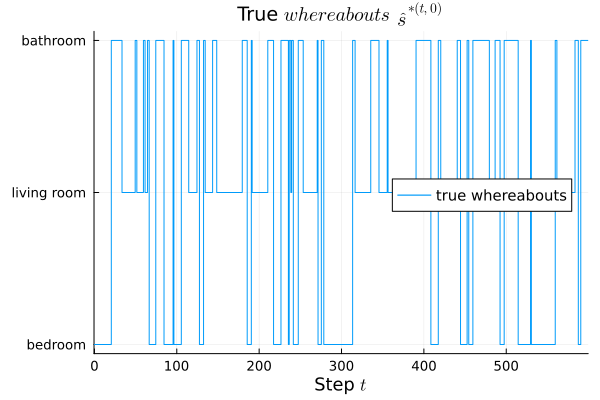

In [16]:
rooms = [argmax(Lŝˣ[whereabouts_n]) for Lŝˣ in parent(Lŝˣː)] ## 1-based index of ŝ^{*(t,0)}
plot(step_x(T+1), step_y(rooms),
    linetype=:steppost, legend=:right,
    label="true whereabouts",
    xlabel="Step \$t\$",
    xticks=0:100:T,
    xlims=(-0.5, T + 0.5),
    yticks=(1:3, whereabouts_labels),
    title="True \$\\mathit{whereabouts}\$ \$\\hat{s}^{*(t,0)}\$")


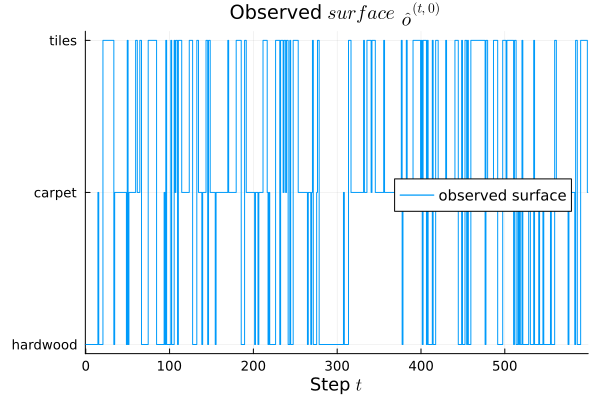

In [17]:
textures = [argmax(Lô[surface_m]) for Lô in parent(Lôː)] ## 1-based index of ô^{(t,0)}
plot(step_x(T+1), step_y(textures),
    linetype=:steppost, legend=:right,
    label="observed surface",
    xlabel="Step \$t\$",
    xticks=0:100:T,
    xlims=(-0.5, T + 0.5),
    yticks=(1:3, surface_labels),
    title="Observed \$\\mathit{surface}\$ \$\\hat{o}^{(t,0)}\$")


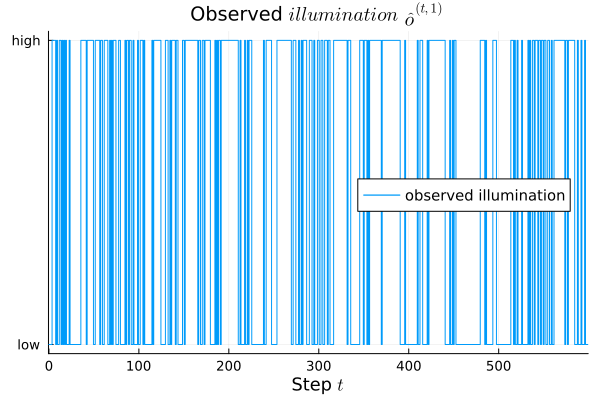

In [18]:
lights = [argmax(Lô[illumination_m]) for Lô in parent(Lôː)] ## 1-based index of ô^{(t,1)}
plot(step_x(T+1), step_y(lights),
    linetype=:steppost, legend=:right,
    label="observed illumination",
    xlabel="Step \$t\$",
    xticks=0:100:T,
    xlims=(-0.5, T + 0.5),
    yticks=(1:2, illumination_labels),
    title="Observed \$\\mathit{illumination}\$ \$\\hat{o}^{(t,1)}\$")


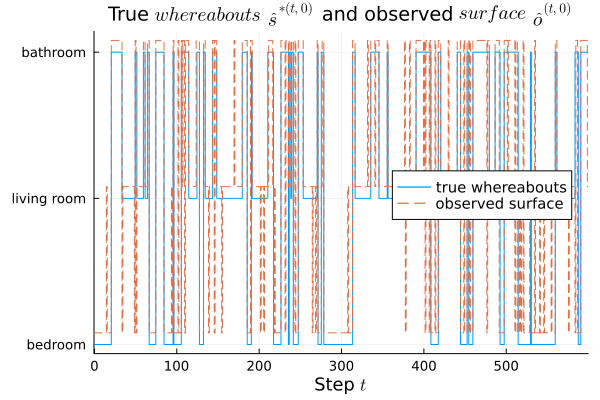

In [19]:
## textures is shifted up by 0.08 so a matching tick does not hide the whereabouts
plot(step_x(T+1), step_y(rooms),
    linetype=:steppost, label="true whereabouts",
    yticks=(1:3, whereabouts_labels),
    xticks=0:100:T,
    xlims=(-0.5, T + 0.5),
    title="True \$\\mathit{whereabouts}\$ \$\\hat{s}^{*(t,0)}\$ and observed \$\\mathit{surface}\$ \$\\hat{o}^{(t,0)}\$")
plot!(step_x(T+1), step_y(textures .+ 0.08),
    linetype=:steppost, linestyle=:dash, label="observed surface",
    xlabel="Step \$t\$", legend=:right)


In [20]:
mistakes = count(rooms .!= textures)
println("camera mistakes: $mistakes of $(T+1) ticks ($(round(100*mistakes/(T+1), digits=1))%)")

camera mistakes: 56 of 600 ticks (9.3%)


In [21]:
## Fractions of "high" should sit near 0.50, 0.85, and 0.10.
## They are a sample, so they will not match A^{*(1)} exactly.
## Uses rooms and lights from the plot cells above.
for (r, place) in enumerate(whereabouts_labels)
    in_place  = rooms .== r
    frac_high = mean(lights[in_place] .== 2) ## argmax 2 is "high"
    println("$place: high $(round(frac_high, digits=2)) of $(count(in_place)) ticks (A^{*(1)}: $(_Aˣı1ı[2, r]))")
end


bedroom: high 0.52 of 188 ticks (A^{*(1)}: 0.5)
living room: high 0.91 of 226 ticks (A^{*(1)}: 0.85)
bathroom: high 0.07 of 186 ticks (A^{*(1)}: 0.1)


### 4.4 Uncertainty Model

The randomness in the simulated data is drawn in `execute` (and in the $t = 0$ block of `create_envir`) from one `MersenneTwister`. The next *whereabouts* is a categorical draw from a column of $\boldsymbol{B}^{\ast(0)}$. Each observation is a categorical draw from a column of $\boldsymbol{A}^{\ast(0)}$ or $\boldsymbol{A}^{\ast(1)}$. The initial *whereabouts* is fixed, so that draw is not random: $\boldsymbol{D}^{\ast(0)}$ is a one-hot.

On seed 42 the simulated path spends 188 ticks with *whereabouts* "bedroom", 226 with "living room", and 186 with "bathroom". The share of *illumination* "high" on those ticks is 0.52, 0.91, and 0.07, next to the columns 0.50, 0.85, and 0.10. The camera's *surface* disagrees with the *whereabouts* on 56 ticks.

The agent is not given those matrices. Section 4.5.4 sets a different prior on purpose. $\check{\boldsymbol{a}}^{(0)}$ trusts the camera and is peaked on the correct *surface*. $\check{\boldsymbol{a}}^{(1)}$ and $\check{\boldsymbol{b}}^{(0)}$ are matrices of ones, so *illumination* and the transitions are learned from the observations. The agent's $\boldsymbol{D}^{(0)}$ is uniform, while the environment always starts at "bedroom".


### 4.5 Agent / Generative Model
#### 4.5.1 State and Observation variables

The agent does not know $s^{(t,0)}$. It carries a categorical random variable for that factor,

$$
\mathbf{s}^{(t)} = \big(s^{(t,0)}\big), \qquad s^{(t,0)} \in \{\text{bedroom}, \text{living room}, \text{bathroom}\}
$$

and a belief $\boldsymbol{s}^{(t,0)} \in [0, 1]^{3}$. The belief is the marginal of a structured posterior over the whole trajectory, not a separate filter step. One factor, one modality pair, and a batch of 600 ticks is small enough that the trajectory stays joint inside $Q(s^{(0:T,0)})$. A mean-field factorization over time is not required for tractability here, and it would throw away the transition evidence that corrects a misread. The matrices are factorized out of the states, which is the approximation that makes learning tractable. Section 4.5.5 writes it down.

The initial prior is

$$
P_D\big(s^{(0,0)}\big) = \mathcal{Cat}\big(s^{(0,0)};\, \boldsymbol{D}^{(0)}\big), \qquad \boldsymbol{D}^{(0)} = \big[\tfrac{1}{3}, \tfrac{1}{3}, \tfrac{1}{3}\big]^{\top}
$$

The agent is not told that the Roomba starts at "bedroom".

The observations the agent conditions on are the environment's $\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{(t,0)}, \hat{\boldsymbol{o}}^{(t,1)}\big)$, with the same values as in section 4.3.1.


#### 4.5.2 Decision variables

The agent selects no action and no policy. There is no horizon $H$ and no decision matrix $\boldsymbol{V}$.


The loop records the Roomba's motion and then infers. It does not steer.


#### 4.5.3 Preference variables / Setpoints

There is no preference vector $\log\boldsymbol{C}$, and there is no habit vector $\boldsymbol{E}$. Both modalities are used for perception. Nothing is treated as a setpoint.


A preference would not change the inference in this part, because the agent never scores a policy.


#### 4.5.4 State Transition and Observation Generation functions

The agent's transition, for $t > 0$, is

$$
P\big(s^{(t,0)} \mid s^{(t-1,0)}, \boldsymbol{B}^{(0)}\big) = \mathcal{Cat}\big(s^{(t,0)};\, \boldsymbol{B}^{(0)}[\bullet, s^{(t-1,0)}]\big)
$$

$\boldsymbol{B}^{(0)}[\bullet, s^{(t-1,0)}]$ is the column of $\boldsymbol{B}^{(0)}$ for the previous *whereabouts*. The observation model, for $m \in \{0, 1\}$, is

$$
P\big(o^{(t,m)} \mid s^{(t,0)}, \boldsymbol{A}^{(m)}\big) = \mathcal{Cat}\big(o^{(t,m)};\, \boldsymbol{A}^{(m)}[\bullet, s^{(t,0)}]\big)
$$

$\boldsymbol{A}^{(m)}[\bullet, s^{(t,0)}]$ is the column for the current *whereabouts*: three *surface* probabilities when $m = 0$, two *illumination* probabilities when $m = 1$.

The agent does not know the column, because it does not know $s^{(t,0)}$. Multiplying by the belief averages the columns. $\boldsymbol{B}^{(0)}\boldsymbol{s}^{(t-1,0)}$ is the predicted belief about the next *whereabouts*. $\boldsymbol{A}^{(0)}\boldsymbol{s}^{(t,0)}$ and $\boldsymbol{A}^{(1)}\boldsymbol{s}^{(t,0)}$ are the expected *surface* and the expected *illumination*. The numerical example in section 4.1 is that product for $\boldsymbol{A}^{(0)}$.

Given the *whereabouts*, the sensors are independent, so

$$
P\big(o^{(t,0)}, o^{(t,1)} \mid s^{(t,0)}\big) = P\big(o^{(t,0)} \mid s^{(t,0)}, \boldsymbol{A}^{(0)}\big)\, P\big(o^{(t,1)} \mid s^{(t,0)}, \boldsymbol{A}^{(1)}\big)
$$

A value of *whereabouts* that explains both readings gains belief. A value that explains only one of them loses some. That product is how *illumination* can move the belief when the camera is unsure.

$\boldsymbol{A}^{(0)}$, $\boldsymbol{A}^{(1)}$, and $\boldsymbol{B}^{(0)}$ are random, with Dirichlet priors. The concentrations are pseudo-counts, imagined observations the agent has before the data.

For $\boldsymbol{B}^{(0)}$ every entry of $\check{\boldsymbol{b}}^{(0)}$ is 1. Every transition is equally likely on average, and the prior is weak, so the 600 ticks overrule it.

For the camera, $\check{\boldsymbol{a}}^{(0)}$ has 10 on the diagonal and 1 off it. Correct readings start with more pseudo-counts than mistakes, and mistakes remain possible.

For the light sensor, every entry of $\check{\boldsymbol{a}}^{(1)}$ is 1. The agent does not know in advance which rooms are bright. It learns $\boldsymbol{A}^{(1)}$ from the data, with the camera anchoring the *whereabouts*. Comparing $\bar{\boldsymbol{A}}^{(1)}$ with $\boldsymbol{A}^{\ast(1)}$ afterwards is the check.

Normalizing a preference is not at issue: there is no $\log\boldsymbol{C}$.

**Inference.** The variational posterior factorizes as

$$
Q\big(s^{(0:T,0)}, \boldsymbol{A}^{(0)}, \boldsymbol{A}^{(1)}, \boldsymbol{B}^{(0)}\big) = Q\big(s^{(0:T,0)}\big)\, Q\big(\boldsymbol{A}^{(0)}\big)\, Q\big(\boldsymbol{A}^{(1)}\big)\, Q\big(\boldsymbol{B}^{(0)}\big)
$$

$Q(s^{(0:T,0)})$ keeps the dependencies along the trajectory. That is the structured part. The three matrices are independent of the states and of each other under $Q$.

**Planning.** There is no policy, so there is no expected free energy and no action posterior. Section 4.5.6 says this in one place.


#### 4.5.5 Implementation of the Agent / Generative Model / Internal Model

The generative model of one run is

$$
\begin{aligned}
&P\big(o^{(0:T,0)}, o^{(0:T,1)}, s^{(0:T,0)}, \boldsymbol{A}^{(0)}, \boldsymbol{A}^{(1)}, \boldsymbol{B}^{(0)}\big) \\[4pt]
&\quad= \underbrace{P_{\check{a}^{(0)}}\big(\boldsymbol{A}^{(0)}\big)\, P_{\check{a}^{(1)}}\big(\boldsymbol{A}^{(1)}\big)\, P_{\check{b}^{(0)}}\big(\boldsymbol{B}^{(0)}\big)}_{\text{parameter prior}}
   \,\underbrace{P_D\big(s^{(0,0)}\big)}_{\substack{\text{state}\\ \text{prior}}}
   \prod_{t=0}^{T} \prod_{m=0}^{1} \underbrace{P_{A^{(m)}}\big(o^{(t,m)} \mid s^{(t,0)}\big)}_{\substack{\text{observation}\\ \text{model}}}
   \prod_{t=1}^{T} \underbrace{P_{B^{(0)}}\big(s^{(t,0)} \mid s^{(t-1,0)}\big)}_{\substack{\text{state}\\ \text{transition}}} \\[6pt]
&\quad= P_{\check{a}^{(0)}}\big(\boldsymbol{A}^{(0)}\big)\, P_{\check{a}^{(1)}}\big(\boldsymbol{A}^{(1)}\big)\, P_{\check{b}^{(0)}}\big(\boldsymbol{B}^{(0)}\big)
   \, P_D\big(s^{(0,0)}\big)
   \prod_{t=0}^{T} \prod_{m=0}^{1} P\big(o^{(t,m)} \mid s^{(t,0)}, \boldsymbol{A}^{(m)}\big)
   \prod_{t=1}^{T} P\big(s^{(t,0)} \mid s^{(t-1,0)}, \boldsymbol{B}^{(0)}\big)
\end{aligned}
$$

with

$$
P_{\check{a}^{(m)}}\big(\boldsymbol{A}^{(m)}\big) = \mathcal{Dir}\big(\boldsymbol{A}^{(m)};\, \check{\boldsymbol{a}}^{(m)}\big), \quad m = 0, 1, \qquad
P_{\check{b}^{(0)}}\big(\boldsymbol{B}^{(0)}\big) = \mathcal{Dir}\big(\boldsymbol{B}^{(0)};\, \check{\boldsymbol{b}}^{(0)}\big)
$$

In the code the Dirichlet prior is a `DirichletCollection`: one Dirichlet distribution on each column. $\boldsymbol{D}^{(0)}$ is the uniform vector from section 4.5.1 and is not learned, so it stays a subscript.

The two lines are the same factorization. The first names the matrix in the subscript. The second writes $\boldsymbol{A}^{(0)}$, $\boldsymbol{A}^{(1)}$, and $\boldsymbol{B}^{(0)}$ as conditions, because they are random. The product over $m$ is the combination of the two sensors: at each tick both observations depend on $s^{(t,0)}$, and given that value they are independent.

The three steps in a full agent are perception, planning, and decision. This part has perception only, and it is batched. `compute` runs variational inference on the model above for all $T + 1$ ticks, for 20 iterations, and returns the last iteration.


The model uses categorical distributions for $s^{(t,0)}$, $o^{(t,0)}$, and $o^{(t,1)}$, and `DirichletCollection` priors for the three matrices, with the concentrations from section 4.5.4.

The constraints are the structured factorization already stated: the trajectory $s^{(0:T,0)}$ stays one factor, and each matrix is its own factor. RxInfer's `vague` initialization is only a starting marginal for the iterations. The priors above are part of the model.


In [22]:
@model function hidden_markov_model(oı0ıː, oı1ıː, T)
    _Bı0ı ~ DirichletCollection(ones(3, 3))       ## P_{b̌^{(0)}}(B^{(0)}), b̌^{(0)} = all ones
    _Aı0ı ~ DirichletCollection([10.0  1.0  1.0;
                                  1.0 10.0  1.0;
                                  1.0  1.0 10.0]) ## P_{ǎ^{(0)}}(A^{(0)}): surface, trusted camera
    _Aı1ı ~ DirichletCollection(ones(2, 3))       ## P_{ǎ^{(1)}}(A^{(1)}): illumination, flat prior

    sː[1]  ~ Categorical(fill(1.0/3.0, 3))        ## t = 0: P_D(s^{(0,0)}), uniform
    oı0ıː[1] ~ DiscreteTransition(sː[1], _Aı0ı)   ## t = 0: P(o^{(0,0)} | s^{(0,0)}, A^{(0)})
    oı1ıː[1] ~ DiscreteTransition(sː[1], _Aı1ı)   ## t = 0: P(o^{(0,1)} | s^{(0,0)}, A^{(1)})
    for t in 1:T
        sː[t+1]  ~ DiscreteTransition(sː[t], _Bı0ı)      ## P(s^{(t,0)} | s^{(t-1,0)}, B^{(0)})
        oı0ıː[t+1] ~ DiscreteTransition(sː[t+1], _Aı0ı)  ## P(o^{(t,0)} | s^{(t,0)}, A^{(0)})
        oı1ıː[t+1] ~ DiscreteTransition(sː[t+1], _Aı1ı)  ## P(o^{(t,1)} | s^{(t,0)}, A^{(1)})
    end
end

@constraints function hidden_markov_model_constraints()
    q(sː, _Aı0ı, _Aı1ı, _Bı0ı) = q(sː)q(_Aı0ı)q(_Aı1ı)q(_Bı0ı)
end


hidden_markov_model_constraints (generic function with 1 method)

**Notes on the agent code.**

The model holds random variables, not tuples, so a member index sits in the name.

- `sː`, `oı0ıː`, and `oı1ıː` have no hat and no `_`. They are $s^{(0:T,0)}$, $o^{(0:T,0)}$, and $o^{(0:T,1)}$. The data fill in the observations. In the model those names are still the variables being observed.
- `_Aı0ı`, `_Aı1ı`, and `_Bı0ı` are $\boldsymbol{A}^{(0)}$, $\boldsymbol{A}^{(1)}$, and $\boldsymbol{B}^{(0)}$.
- `sː[t+1]` holds $s^{(t,0)}$. The storage index is `t+1` because the vector inside RxInfer starts at 1. The loop variable `t` is the mathematical $t$, and the loop `for t in 1:T` is the product from $t = 1$ to $T$. Time 0 is the block above the loop.
- Both observations at a tick attach to the same `sː[t+1]`. That is the product over $m$.
- The constraint `q(sː)q(_Aı0ı)q(_Aı1ı)q(_Bı0ı)` is $Q(s^{(0:T,0)})\,Q(\boldsymbol{A}^{(0)})\,Q(\boldsymbol{A}^{(1)})\,Q(\boldsymbol{B}^{(0)})$.

The data are passed under the model's observation names: `data = (oı0ıː = _ôı0ıː_data, oı1ıː = _ôı1ıː_data)`.

The node is `DiscreteTransition`. Older RxInfer versions called it `Transition`.


`create_agent` takes the two 1-based observation vectors and returns `compute`. `compute` runs 20 iterations and keeps the last one, including the Bethe free energy.


In [23]:
function create_agent(; _ôı0ıː_data, _ôı1ıː_data)
    @assert length(_ôı0ıː_data) == length(_ôı1ıː_data) "both sensors must cover the same ticks"
    T = length(_ôı0ıː_data) - 1    ## observations at t = 0, ..., T

    compute = () -> begin
        imarginals = @initialization begin
            q(_Aı0ı) = DirichletCollection(ones(3, 3)) ## surface: 3 values × 3 whereabouts
            q(_Aı1ı) = DirichletCollection(ones(2, 3)) ## illumination: 2 values × 3 whereabouts
            q(_Bı0ı) = DirichletCollection(ones(3, 3))
            q(sː)    = vague(Categorical, 3)
        end
        infer(
            model          = hidden_markov_model(T=T),
            data           = (oı0ıː = _ôı0ıː_data, oı1ıː = _ôı1ıː_data),
            constraints    = hidden_markov_model_constraints(),
            initialization = imarginals,
            returnvars     = (_Aı0ı = KeepLast(), _Aı1ı = KeepLast(), _Bı0ı = KeepLast(), sː = KeepLast()),
            iterations     = 20,
            free_energy    = true,
        )
    end

    return compute
end


create_agent (generic function with 1 method)

#### 4.5.6 Expected free energy and action selection

This part does not select an action. There is no policy, no horizon, no $\boldsymbol{G}$, no $\boldsymbol{G}_{\Sigma}$, and no $Q(u^{(t)})$. The agent infers $Q(s^{(0:T,0)})$ and the three matrix posteriors, and then stops. Expected free energy and action selection belong to a later part, once `act` and `slide` exist.


### 4.6 Agent Evaluation

`create_agent` returns `compute`. One call conditions on $\hat{\mathbf{o}}^{(0:T)}$ and returns $Q(s^{(t,0)})$ at every tick, the posterior means $\bar{\boldsymbol{A}}^{(0)}$, $\bar{\boldsymbol{A}}^{(1)}$, and $\bar{\boldsymbol{B}}^{(0)}$, and the Bethe free energy over 20 iterations. The free energy should fall and then level off. That is a check on the optimization, not the designer's $J_{\text{track}}$.

The detail below is one path, seed 42, $T = 599$. A single path is for reading the beliefs. The comparison with the camera-only agent uses this same path, so the two agents see the same $\hat{\boldsymbol{o}}^{(t,0)}$. It is not an average over seeds. Section 4.7 says what that does and does not show.


The environment is simulated once. The two-sensor agent sees both modalities. The camera-only agent, later in this section, sees *surface* only, from the same `Lôː`.


##### A baseline that reads the *surface*

Map "hardwood" to "bedroom", "carpet" to "living room", and "tiles" to "bathroom". The indices are lined up the same way in `whereabouts_labels` and `surface_labels`, so this baseline is correct exactly when `rooms .== textures`. On the seed-42 path the camera is wrong at 56 of 600 ticks, which is 9.3%, so the baseline's tracking is 90.7%. The printout in the simulation section reports that count. The agents below are scored against this baseline and against each other.


##### The two-sensor agent

`compute` sees `_ôı0ıː_data` and `_ôı1ıː_data`. The initial marginals passed to `infer` are vague. The priors that matter are the ones inside `@model`.


In [24]:
## ---------- simulation parameters ----------
## t = 0, ..., T (600 ticks)
T = 599

## Initial whereabouts: "bedroom"
Lŝˣ₀ = tuple0([1.0, 0.0, 0.0]) ## ŝ^{*(0)} = (ŝ^{*(0,0)})


1-element OffsetArray(::Vector{Vector{Float64}}, 0:0) with eltype Vector{Float64} with indices 0:0:
 [1.0, 0.0, 0.0]

In [26]:
## ---------- overrides ----------


The posterior means $\bar{\boldsymbol{B}}^{(0)}$, $\bar{\boldsymbol{A}}^{(0)}$, and $\bar{\boldsymbol{A}}^{(1)}$ should sit close to $\boldsymbol{B}^{\ast(0)}$, $\boldsymbol{A}^{\ast(0)}$, and $\boldsymbol{A}^{\ast(1)}$. *Illumination* is the sharp test: $\check{\boldsymbol{a}}^{(1)}$ was a matrix of ones.


In [25]:
## Environment: t = 0, ..., T, seed 42
(execute_ai, observe_ai, state_ai) = create_envir(; LAˣ=LAˣ, LBˣ=LBˣ, Lŝˣ₀=Lŝˣ₀)
Lŝˣː = offset0(Vector{Any}(undef, T+1)) ## ŝ^{*(0:T)}
Lôː  = offset0(Vector{Any}(undef, T+1)) ## ô^{(0:T)}
for t = 0:T
    t > 0 && execute_ai()
    Lŝˣː[t] = state_ai()
    Lôː[t]  = observe_ai()
end

## Agent: Q(s^{(t,0)}) and the three matrix posteriors, from every observation at once
_ôı0ıː_data = [Lô[surface_m] for Lô in parent(Lôː)]       ## surface, 1-based copy
_ôı1ıː_data = [Lô[illumination_m] for Lô in parent(Lôː)] ## illumination, 1-based copy
compute_ai = create_agent(; _ôı0ıː_data=_ôı0ıː_data, _ôı1ıː_data=_ôı1ıː_data)
result     = compute_ai()


Inference results:
  Posteriors       | available for (_Aı0ı, _Aı1ı, sː, _Bı0ı)
  Free Energy:     | [1121.44, 1119.37, 1116.29, 1109.73, 1092.09, 1036.19, 911.191, 808.592, 734.419, 698.589, 689.867, 688.444, 688.257, 688.237, 688.235, 688.235, 688.235, 688.235, 688.235, 688.235]


In [26]:
[Lŝˣ[whereabouts_n] for Lŝˣ in Lŝˣː] ## ŝ^{*(t,0)} for t = 0, ..., T


600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 ⋮
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]

In [27]:
[Lô[surface_m] for Lô in Lôː] ## ô^{(t,0)} for t = 0, ..., T


600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 ⋮
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 1.0, 0.0]

In [28]:
[Lô[illumination_m] for Lô in Lôː] ## ô^{(t,1)} for t = 0, ..., T


600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [0.0, 1.0]
 [0.0, 1.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [0.0, 1.0]
 ⋮
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]

In [29]:
result.posteriors

Dict{Symbol, Any} with 4 entries:
  :_Aı0ı => DirichletCollection{Float64, 2, Matrix{Float64}}(…
  :_Aı1ı => DirichletCollection{Float64, 2, Matrix{Float64}}(…
  :sː    => Categorical{Float64, Vector{Float64}}[Categorical{Float64, Vector{F…
  :_Bı0ı => DirichletCollection{Float64, 2, Matrix{Float64}}(…

In [30]:
println("Posterior mean of B^{(0)} (whereabouts transitions):")
_B̄ı0ı = mean(result.posteriors[:_Bı0ı]) ## B̄^{(0)} = E_Q[B^{(0)}], compared with B^{*(0)}


Posterior mean of B^{(0)} (whereabouts transitions):


3×3 Matrix{Float64}:
 0.907447    0.00535329  0.0854277
 0.00554357  0.918301    0.0941925
 0.0870099   0.0763455   0.82038

This compares well with:

```julia
_Bˣı0ı = [
    0.9  0.0  0.1;
    0.0  0.9  0.1;
    0.1  0.1  0.8]
```


In [31]:
println("Posterior mean of A^{(0)} (surface likelihood):")
_Āı0ı = mean(result.posteriors[:_Aı0ı]) ## Ā^{(0)} = E_Q[A^{(0)}], compared with A^{*(0)}


Posterior mean of A^{(0)} (surface likelihood):


3×3 Matrix{Float64}:
 0.880903   0.045862   0.0622937
 0.0654938  0.932655   0.0462148
 0.0536034  0.0214828  0.891491

This compares well with:

```julia
_Aˣı0ı = [
    0.9  0.05 0.05;
    0.05 0.9  0.05;
    0.05 0.05 0.9]
```


In [32]:
println("Posterior mean of A^{(1)} (illumination likelihood):")
_Āı1ı = mean(result.posteriors[:_Aı1ı]) ## Ā^{(1)} = E_Q[A^{(1)}], compared with A^{*(1)}


Posterior mean of A^{(1)} (illumination likelihood):


2×3 Matrix{Float64}:
 0.487316  0.0872031  0.932169
 0.512684  0.912797   0.0678307

This compares well with:

```julia
_Aˣı1ı = [
    0.5  0.15 0.9;
    0.5  0.85 0.1]
```


$J_{\text{track}}$ compares $i^{\star}(t)$ with $\hat{s}^{\ast(t,0)}$. $J_{\text{misread}}$ uses the ticks in $\mathcal{W}$, where the *surface* index and the *whereabouts* index differ. The figure shows the most probable *whereabouts* against the true one, and the Bethe free energy across iterations. The shading in the first panel is $s^{(t,0)[i]}$.


In [33]:
Lsː            = offset0(result.posteriors[:sː]) ## Q(s^{(t,0)}), t = 0, ..., T
rooms          = [argmax(Lŝˣ[whereabouts_n]) for Lŝˣ in parent(Lŝˣː)]
inferred_rooms = [argmax(ReactiveMP.probvec(q)) for q in parent(Lsː)]
accuracy       = mean(inferred_rooms .== rooms)

textures            = [argmax(Lô[surface_m]) for Lô in parent(Lôː)]
camera_wrong        = textures .!= rooms
accuracy_when_wrong = mean(inferred_rooms[camera_wrong] .== rooms[camera_wrong])
println("camera misread the surface at $(count(camera_wrong)) of $(T+1) ticks; ",
        "agent still inferred the right whereabouts at $(round(100*accuracy_when_wrong, digits=1))% of those")

## z has size (length(0:T), 3): Plots reads heatmap(x, y, z) as z[x, y]
prob = reduce(hcat, [collect(ReactiveMP.probvec(q)) for q in parent(Lsː)]) ## 3 × (T+1)
p1 = heatmap(0:T, 1:3, permutedims(prob),
    c=:Greens, clims=(0, 1),
    yticks=(1:3, whereabouts_labels),
    xticks=0:100:T,
    xlims=(-0.5, T + 0.5),
    colorbar=:bottom,
    colorbar_title="shading: probability \$s^{(t,0)[i]}\$ of value \$i\$",
    title="Belief \$\\mathbf{\\mathit{s}}^{(t,0)}\$ about \$\\mathit{whereabouts}\$ (shading), true \$\\hat{s}^{*(t,0)}\$ (line)",
    size=(900, 420))
plot!(p1, step_x(T+1), step_y(Float64.(rooms)),
    color=:black, linewidth=1.5, label="true whereabouts", linetype=:steppost)
scatter!(p1, (findall(camera_wrong) .- 1), rooms[camera_wrong],
    color=:gray, markersize=3, markerstrokewidth=0, label="camera misread")

p2 = plot(result.free_energy,
    label="Bethe free energy",
    xlabel="Iteration",
    legend=:right)
plot(p1, p2, layout=@layout([a; b]), size=(900, 700))
println("J_track = $(round(100*accuracy, digits=1))%")


camera misread the surface at 56 of 600 ticks; agent still inferred the right whereabouts at 75.0% of those
J_track = 97.2%


In the plot above, look for three things.

- The black line should sit on the dark green row. That is $J_{\text{track}}$: the most probable value of $\boldsymbol{s}^{(t,0)}$ against $\hat{s}^{\ast(t,0)}$.
- Gray dots are ticks where the *surface* does not match the *whereabouts*. The green mass should stay on the true row through many of those dots. That is the transition model correcting the camera, before *illumination* is even separated out.
- The Bethe free energy in the lower panel should drop over the 20 iterations and then flatten. On this seed, $J_{\text{track}} = 97.2\%$: the inferred *whereabouts* is wrong at 17 of 600 ticks, and it is still right at 75.0% of the 56 ticks where the camera misread the *surface*.


##### The same observations, with and without *illumination*

The two-sensor run above is one path. An earlier camera-only run drew a different path, because adding a second sensor changes the order of the random draws inside `execute`. To isolate the light sensor, the camera-only agent below receives only $\hat{\boldsymbol{o}}^{(t,0)}$ from this same `Lôː` and ignores $\hat{\boldsymbol{o}}^{(t,1)}$.

The comparison has three pieces.

- **Accuracy**, overall and split by whether the camera's *surface* matched the *whereabouts*. The split $\mathcal{W}$ is where a second sensor has something to add.
- **Which errors change.** Ticks the light sensor fixes, and ticks it gets wrong that the camera-only agent had right.
- **Confidence.** The probability each agent assigns to $\hat{s}^{\ast(t,0)}$ over time.


In [34]:
@model function hidden_markov_model_camera(oı0ıː, T)
    _Bı0ı ~ DirichletCollection(ones(3, 3)) ## P_{b̌^{(0)}}(B^{(0)}), b̌^{(0)} = all ones
    _Aı0ı ~ DirichletCollection([10.0  1.0  1.0;
                                  1.0 10.0  1.0;
                                  1.0  1.0 10.0]) ## P_{ǎ^{(0)}}(A^{(0)}): surface, trusted camera

    sː[1]  ~ Categorical(fill(1.0/3.0, 3)) ## t = 0: P_D(s^{(0,0)}), uniform
    oı0ıː[1] ~ DiscreteTransition(sː[1], _Aı0ı) ## t = 0: P(o^{(0,0)} | s^{(0,0)}, A^{(0)})
    for t in 1:T
        sː[t+1]  ~ DiscreteTransition(sː[t], _Bı0ı)    ## P(s^{(t,0)} | s^{(t-1,0)}, B^{(0)})
        oı0ıː[t+1] ~ DiscreteTransition(sː[t+1], _Aı0ı) ## P(o^{(t,0)} | s^{(t,0)}, A^{(0)})
    end
end

@constraints function hidden_markov_model_camera_constraints()
    q(sː, _Aı0ı, _Bı0ı) = q(sː)q(_Aı0ı)q(_Bı0ı)
end


hidden_markov_model_camera_constraints (generic function with 1 method)

In [35]:
imarginals_cam = @initialization begin
    q(_Aı0ı) = DirichletCollection(ones(3, 3))
    q(_Bı0ı) = DirichletCollection(ones(3, 3))
    q(sː)    = vague(Categorical, 3)
end

result_cam = infer(
    model          = hidden_markov_model_camera(T=T),
    data           = (oı0ıː = _ôı0ıː_data,), ## surface only, same ticks as the two-sensor agent
    constraints    = hidden_markov_model_camera_constraints(),
    initialization = imarginals_cam,
    returnvars     = (_Aı0ı = KeepLast(), _Bı0ı = KeepLast(), sː = KeepLast()),
    iterations     = 20,
    free_energy    = true,
)


Inference results:
  Posteriors       | available for (_Aı0ı, sː, _Bı0ı)
  Free Energy:     | [699.022, 696.943, 695.104, 693.372, 691.508, 689.068, 685.099, 677.089, 656.923, 598.497, 489.104, 436.346, 426.686, 424.194, 423.594, 423.498, 423.486, 423.485, 423.484, 423.484]


In [36]:
using Printf

## plain vectors over t = 0, ..., T, aligned
rooms         = [argmax(Lŝˣ[whereabouts_n]) for Lŝˣ in parent(Lŝˣː)]
textures      = [argmax(Lô[surface_m]) for Lô in parent(Lôː)]
camera_wrong  = textures .!= rooms
inferred_cam  = [argmax(ReactiveMP.probvec(q)) for q in result_cam.posteriors[:sː]]
inferred_both = [argmax(ReactiveMP.probvec(q)) for q in result.posteriors[:sː]]
correct_cam   = inferred_cam  .== rooms
correct_both  = inferred_both .== rooms

masks  = [trues(T+1), .!camera_wrong, camera_wrong]
labels = ["all ticks", "camera right", "camera wrong"]

println("Accuracy of the inferred whereabouts (same data for both agents)\n")
@printf("%-14s %6s | %-24s | %-24s\n", "ticks", "n", "camera only", "camera + light")
println("-"^76)
for (label, m) in zip(labels, masks)
    n = count(m)
    e_cam, e_both = count(.!correct_cam .& m), count(.!correct_both .& m)
    @printf("%-14s %6d | errors %4d  acc %5.1f%% | errors %4d  acc %5.1f%%\n",
            label, n, e_cam, 100*(n-e_cam)/n, e_both, 100*(n-e_both)/n)
end

fixed  = .!correct_cam .& correct_both ## wrong with the camera only, right with both sensors
broken = correct_cam .& .!correct_both ## right with the camera only, wrong with both sensors
println("\nticks fixed by the light sensor:     $(count(fixed))")
println("new errors with the light sensor:    $(count(broken))")

## J_B and J_A: largest absolute entrywise gap
err(Ā, Aˣ) = maximum(abs.(Ā .- Aˣ))
println("\nlargest absolute error in the learned matrices")
@printf("  B^{(0)}: camera only %.3f | camera + light %.3f\n",
        err(mean(result_cam.posteriors[:_Bı0ı]), _Bˣı0ı), err(mean(result.posteriors[:_Bı0ı]), _Bˣı0ı))
@printf("  A^{(0)}: camera only %.3f | camera + light %.3f\n",
        err(mean(result_cam.posteriors[:_Aı0ı]), _Aˣı0ı), err(mean(result.posteriors[:_Aı0ı]), _Aˣı0ı))


Accuracy of the inferred whereabouts (same data for both agents)

ticks               n | camera only              | camera + light          
----------------------------------------------------------------------------
all ticks         600 | errors   18  acc  97.0% | errors   17  acc  97.2%
camera right      544 | errors    4  acc  99.3% | errors    3  acc  99.4%
camera wrong       56 | errors   14  acc  75.0% | errors   14  acc  75.0%

ticks fixed by the light sensor:     7
new errors with the light sensor:    6

largest absolute error in the learned matrices
  B^{(0)}: camera only 0.032 | camera + light 0.024
  A^{(0)}: camera only 0.022 | camera + light 0.033


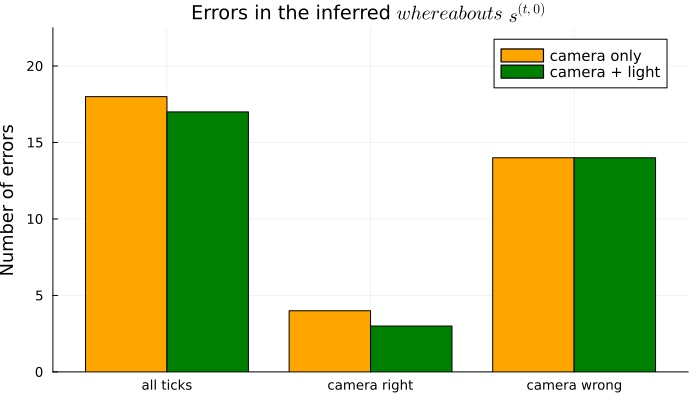

In [37]:
e_cam  = [count(.!correct_cam  .& m) for m in masks]
e_both = [count(.!correct_both .& m) for m in masks]
x = 1:3
bar(x .- 0.2, e_cam,  bar_width=0.4, label="camera only", color=:orange)
bar!(x .+ 0.2, e_both, bar_width=0.4, label="camera + light", color=:green,
     xticks=(x, labels), ylabel="Number of errors",
     ylims=(0, 1.25*maximum(vcat(e_cam, e_both))),
     title="Errors in the inferred \$\\mathit{whereabouts}\$ \$s^{(t,0)}\$",
     legend=:topright, size=(700, 400))


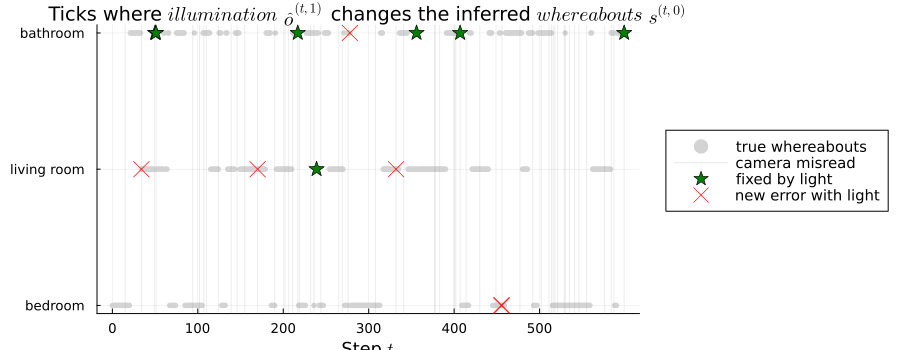

In [38]:
t_of(mask) = findall(mask) .- 1 ## vector positions → times t

scatter(0:T, rooms, markercolor=:lightgray, markersize=3, markerstrokewidth=0,
        label="true whereabouts",
        yticks=(1:3, whereabouts_labels),
        xlabel="Step \$t\$",
        xticks=0:100:T,
        title="Ticks where \$\\mathit{illumination}\$ \$\\hat{o}^{(t,1)}\$ changes the inferred \$\\mathit{whereabouts}\$ \$s^{(t,0)}\$",
        size=(900, 350), legend=:outerright)
vline!(t_of(camera_wrong), color=:gray, alpha=0.15, label="camera misread")
scatter!(t_of(fixed), rooms[fixed], marker=:star5, markercolor=:green, markersize=8,
         label="fixed by light")
scatter!(t_of(broken), rooms[broken], marker=:xcross, markercolor=:red, markersize=8,
         label="new error with light")


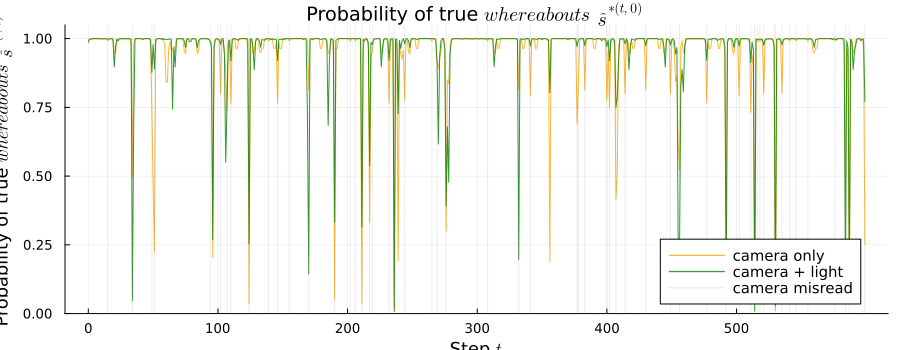

In [39]:
p_true_cam  = [ReactiveMP.probvec(q)[r] for (q, r) in zip(result_cam.posteriors[:sː], rooms)]
p_true_both = [ReactiveMP.probvec(q)[r] for (q, r) in zip(result.posteriors[:sː], rooms)]

p = plot(0:T, p_true_cam, label="camera only", color=:orange, alpha=0.8,
         xlabel="Step \$t\$",
         ylabel="Probability of true \$\\mathit{whereabouts}\$ \$\\hat{s}^{*(t,0)}\$",
         ylim=(0, 1.05),
         xticks=0:100:T,
         title="Probability of true \$\\mathit{whereabouts}\$ \$\\hat{s}^{*(t,0)}\$",
         size=(900, 350), legend=:bottomright)
plot!(p, 0:T, p_true_both, label="camera + light", color=:green, alpha=0.8)
vline!(p, t_of(camera_wrong), color=:gray, alpha=0.15, label="camera misread")


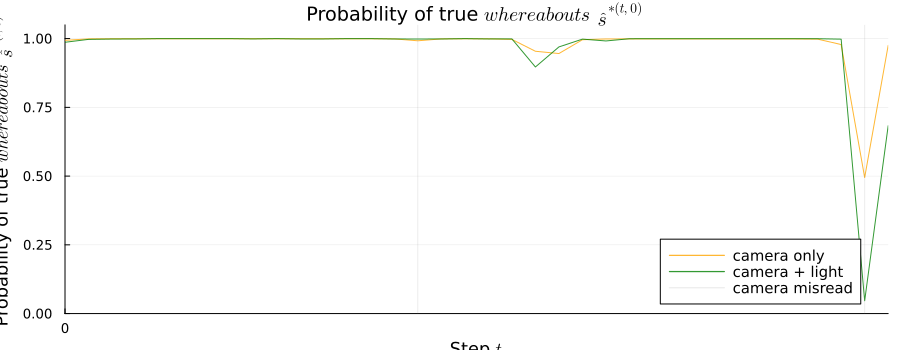

In [40]:
t0 = first(t_of(camera_wrong))
plot!(p, xlims=(max(0, t0-20), min(T, t0+20)))


In the comparison above, look for three things.

- The row *camera wrong* is the place a second sensor can help. There are 56 such ticks. The camera-only agent is still right on 42 of them, which is the transition model discarding a *surface* that does not fit the path. Both agents are wrong on 14.
- *Fixed* and *new errors* are the net effect of *illumination*. On this path the light sensor fixes 7 ticks and introduces 6 new errors.
- The probability of the true *whereabouts* should dip for the camera-only agent at a misread, and dip less, or not at all, when *illumination* agrees with the true room. It can also dip further when *illumination* agrees with the wrong room: a dark living room looks like the bathroom.

The matrix gaps are part of the same comparison. $J_{\text{B}}$ is 0.032 with the camera only and 0.024 with both sensors. $J_{\text{A}}$ is 0.022 with the camera only and 0.033 with both sensors. The extra modality pulls the transition estimate slightly closer to $\boldsymbol{B}^{\ast(0)}$ and the *surface* estimate slightly further from $\boldsymbol{A}^{\ast(0)}$.


### 4.7 Conclusion and outlook

The agent watched a Roomba for 600 ticks through two noisy sensors. It observed *surface* and *illumination*, and it chose nothing. It had to infer the *whereabouts*, which it never saw, and it had to learn $\boldsymbol{A}^{(0)}$, $\boldsymbol{A}^{(1)}$, and $\boldsymbol{B}^{(0)}$ from the same observations. Four ingredients shaped the result:

- **Two sensors with different failure modes.** The camera is usually right and, when it is wrong, it is confidently wrong. The light sensor separates the bathroom from the bedroom only weakly, and it sometimes makes the living room look like the bathroom.
- **A transition matrix with a missing door.** The Roomba usually stays where it is, and it cannot step between the bedroom and the living room. That structure corrects many camera mistakes before the light sensor is asked to.
- **Priors that trust the camera.** $\check{\boldsymbol{a}}^{(0)}$ is peaked on the diagonal. $\check{\boldsymbol{a}}^{(1)}$ and $\check{\boldsymbol{b}}^{(0)}$ are matrices of ones, so those two matrices are learned.
- **One shared path.** The camera-only agent and the two-sensor agent see the same $\hat{\boldsymbol{o}}^{(t,0)}$, seed 42. A gap between them is the light sensor.

Does the light sensor help the agent track the Roomba?

| strategy | errors | $J_{\text{track}}$ | $J_{\text{misread}}$ | $J_{\text{B}}$ | $J_{\text{A}}$ |
|---|---:|---:|---:|---:|---:|
| read the *surface* | 56 | 90.7% | 0% | – | – |
| camera only | 18 | 97.0% | 75.0% | 0.032 | 0.022 |
| camera and light | 17 | 97.2% | 75.0% | 0.024 | 0.033 |

The en dash is a score that strategy does not compute. $J_{\text{misread}}$ for the surface reading is 0%, because that strategy is wrong on every tick in $\mathcal{W}$. Seed 42, 600 ticks.

**On this path the light sensor changes one tick in $J_{\text{track}}$.** The camera-only agent is wrong at 18 of 600 ticks (97.0%). The two-sensor agent is wrong at 17 of 600 (97.2%). The surface-reading baseline is wrong at 56 of 600 (9.3%), so both agents clear that baseline by a wide margin. The margin between the agents is one tick.

**Where the camera is wrong, the two agents match.** On those 56 ticks each agent is wrong 14 times, so $J_{\text{misread}} = 75.0\%$ for both. Of the 544 ticks where the camera is right, the camera-only agent is wrong 4 times and the two-sensor agent 3 times.

**The light sensor fixes 7 ticks and adds 6 new errors.** The fixes do not pile up. A correct *surface* is evidence at about 18 to 1 against one specific wrong surface ($0.90/0.05$). The strongest light reading in the tables is "high" in the living room against the bathroom, about 8.5 to 1 ($0.85/0.10$), and the bedroom's light is 1 to 1. Light rarely overturns the camera, and a misleading light reading can overturn a transition that had the room right.

**The learned *surface* matrix moves a little further from the environment.** $J_{\text{B}}$ falls from 0.032 to 0.024. $J_{\text{A}}$ rises from 0.022 to 0.033. Extra evidence about *whereabouts* tightened the transitions a little and moved $\bar{\boldsymbol{A}}^{(0)}$ a little further from $\boldsymbol{A}^{\ast(0)}$.

**Caveats.** These figures are one seed, seed 42, one apartment, and one draw of 600 ticks. A difference of one tick, or of 7 fixes against 6 new errors, is the size of path noise. The probabilities in section 4.3.4 are assumed. A darker living room, or a light sensor that was right more often than 0.85 and 0.90, would move $J_{\text{misread}}$. The notebook does not average the 30 seeds the series uses for a comparison, so this section does not claim a rate, only what happened on this path.

**Possible next steps:**

- **Thirty seeds.** Repeat the same-data comparison over 30 seeds and report mean $J_{\text{track}}$, $J_{\text{misread}}$, $J_{\text{B}}$, and $J_{\text{A}}$ with the seed count.
- **A light sensor with a stronger true matrix.** Keep the agent's flat prior, change $\boldsymbol{A}^{\ast(1)}$, and see when the fixes outrun the new errors.
- **Online control.** Give the agent `act`, `slide`, a preference over *whereabouts*, and an expected free energy. This part stops at inference.

On the numbers chosen here, a second sensor helps only when its informative readings outweigh its misleading ones, and for this light sensor, on this path, they nearly cancel.


## APPENDIX A: Text conventions and their motivation

Three styles, each with one job. Italic lower case is the name of a model variable, at every use, including in a heading: *whereabouts*, *surface*, *illumination*. Double quotes are a value, and they match the label vectors character for character, so a search for `"living room"` hits the text and the code. Bold is a low-level heading, which opens a paragraph and ends with a full stop, or a label on a bullet or a table row. Italics and bold are not emphasis. This notebook does not underline.

The names were *room*, *texture*, and *light* in the draft this version replaces (written there as Room, Texture, and Light). Each of those words is also needed in its ordinary sense: a room of the apartment, the texture of a floor, the light in a window. A name that is also an ordinary word makes the italics do two jobs. The renames are *whereabouts*, *surface*, and *illumination*. The sensors stay the camera and the light sensor, which are devices, not variables. The values were already lower case in the text, and the label vectors now use those strings: "bedroom", "living room", "bathroom", "hardwood", "carpet", "tiles", "low", "high". The value is "living room", two words, as in the other parts of this series.

Round brackets mark a member of an ordered collection: time, a factor, a modality, time first when both are present. $\boldsymbol{A}^{(0)}$ is modality 0, not $\boldsymbol{A}$ at time 0, because a likelihood does not change with time (rule N). Square brackets mark a position in an array. $s^{(t,0)[i]}$ is the probability of value $i$. An entry, with every index fixed, is plain. A whole array carries no index that means "the whole thing". The draft of this notebook used square brackets for factors and modalities ($s^{[t,0]}$, $\boldsymbol{A}^{[0]}$). That was the previous convention, round brackets for time only, and v1.7 replaces it.

Code follows the same split. `L` is a tuple (upright bold). A leading `_` is an array (italic bold). `ˣ` is the environment's asterisk. `ː` is a trajectory and `ₜ` is the current tick. A member is written with `ı…ı`, as in `_Bˣı0ı` for $\boldsymbol{B}^{\ast(0)}$. A position would be written with `I…I`. Index constants name the member: `whereabouts_n`, `surface_m`, `illumination_m`. `LBˣ[whereabouts_n]` is the same matrix as `_Bˣı0ı`.

The RxInfer model is the exception that has to stay visible. `@model` holds random variables and single matrices, not tuples, and it cannot call `tuple0`. The member index therefore sits in the name: `_Aı0ı`, `_Bı0ı`, `oı0ıː`. Data cross the boundary as `_ôı0ıː_data`, a 1-based `parent` copy. Results cross back through `offset0`. Inside the model, `sː[t+1]` holds time $t$.

This notebook stores one-hots, not category indices. `Lôₜ[surface_m]` is $\hat{\boldsymbol{o}}^{(t,0)}$. The category $\hat{o}^{(t,0)}$ is recovered with `argmax`, which in Julia counts from 1. A later part that stores the category itself should use `ô` for the index and `_ô` for the one-hot. Changing that here would change the arrays passed to `DiscreteTransition`, so the stored one-hots stay.

Keep-comments start with `## `. A single `#` is for a line that is commented out temporarily, apart from the hidden version cell, which is `#| hide` because Quarto requires it. Julia allows `ₜ₋₁` in a name. Single quotes are characters, not strings.


## APPENDIX B: Modeling choices and assumptions, and their motivation

**The apartment has three rooms and no bedroom–living-room door.** *Whereabouts* has three values, and $\boldsymbol{B}^{\ast(0)}$ has zeros in the bedroom–living-room entries. The Roomba reaches the living room only through the bathroom. The stay probabilities are 0.90, 0.90, and 0.80, so a stay in the bedroom lasts about 10 ticks. These numbers are chosen so that a path is sticky and the missing door is absolute. They are not counts from a robot.

**The camera is good and symmetric.** $\boldsymbol{A}^{\ast(0)}$ puts 0.90 on the matching *surface* and 0.05 on each of the other two. The confusable pair for the story is hardwood and tiles, the bedroom and the bathroom. A correct reading against one specific mistake is $0.90/0.05 = 18$.

**The light sensor is real but mild.** $\boldsymbol{A}^{\ast(1)}$ is 0.50/0.50 in the bedroom, 0.15/0.85 in the living room, and 0.90/0.10 in the bathroom. The bedroom carries no light information. The living room is bright except at night or under cloud. The bathroom is dark unless its light is on. The strongest ratio in this table is 8.5, below the camera's 18, which is why section 4.7 finds that light rarely overturns a camera reading. A sharper $\boldsymbol{A}^{\ast(1)}$ was not used. It would have made the second sensor look more helpful than these rooms justify.

**The environment starts at "bedroom", and the agent does not know that.** $\boldsymbol{D}^{\ast(0)} = [1, 0, 0]^{\top}$. The agent's $\boldsymbol{D}^{(0)}$ is uniform. Telling the agent the true start would remove a source of uncertainty the series is here to keep.

**The agent learns the matrices, with a prior that trusts only the camera.** $\check{\boldsymbol{a}}^{(0)}$ is 10 on the diagonal and 1 off it. $\check{\boldsymbol{a}}^{(1)}$ and $\check{\boldsymbol{b}}^{(0)}$ are all ones. The flat light prior is deliberate: if the agent were given $\boldsymbol{A}^{\ast(1)}$, a gain from the light sensor would be the matrix we typed in, not something inferred. The code places a `DirichletCollection` on each matrix, one Dirichlet per column. The joint display in section 4.5.5 writes that prior as $\mathcal{Dir}$.

**The variational family keeps the trajectory and splits the matrices.** $Q(s^{(0:T,0)})$ is structured over time, so a misread can be repaired by the ticks around it. The three matrices are independent of the states under $Q$. A fully factorized state posterior would be cheaper and would throw away the repair. Twenty iterations and `KeepLast` match the previous draft of this notebook.

**$A$ and $B$ follow the active inference convention.** The RxInfer hidden Markov example uses $A$ for transitions. This series uses $\mathbf{A}$ for likelihoods and $\mathbf{B}$ for transitions, including the environment copies $\mathbf{A}^{\ast}$ and $\mathbf{B}^{\ast}$.

**Inference is one batch, not the online cycle.** `act`, `future`, and `slide` are absent. `compute` sees the whole of $\hat{\mathbf{o}}^{(0:T)}$. An online agent would slide the posterior forward one tick at a time and could not revise tick 10 after seeing tick 500. The batch posterior is the right object for "where did it go", and it is a different object from the belief of an agent that has to act at $t$.

**Tuples are built with `tuple0`.** Calling `OffsetVector` directly makes it easy to re-index the one-hot instead of the tuple that contains it. Section 3 records the six reasons. The helper stays.

**The comparison is one seed.** Seed 42, one shared path, 600 ticks. The series asks for 30 seeds before a comparison is treated as a rate. This version does not add that loop: the path already computed is the one section 4.7 discusses, and a 30-seed table would be a new experiment. The next-step bullet in section 4.7 is the place it comes back.

**The stored run, not an earlier write-up, supplies the counts.** The executed comparison prints 18 errors against 17, 14 against 14 on camera-wrong ticks, 7 ticks fixed, and 6 new errors, with $J_{\text{B}}$ 0.032 against 0.024 and $J_{\text{A}}$ 0.022 against 0.033. An earlier paragraph of this notebook said 6 fixes and 5 new errors, and it split those ticks by room. Those sentences do not match this run, and the room split is not computed, so they are not repeated. Re-running seed 42 should reproduce the printed table. If it does not, the table wins and section 4.7 should be edited to it.

**One-hots are what `DiscreteTransition` receives.** The trajectories store $\hat{\boldsymbol{o}}^{(t,m)}$, not the category index. Appendix A says why that stays.
